Sentinela  — Sistema de Prevenção de Churn
Aura Bank | Hackathon de Dados 2026

Somos cinco mulheres de cinco estados do Brasil —
uma engenheira de minas, duas analistas de sistemas,
uma cientista da computação e uma engenheira de software.

Histórias diferentes. Bagagens diferentes.
Mas um objetivo comum: usar dados para resolver
um problema real de negócio.

O problema que vamos atuar:
O Aura Bank (nosso banco fictício) perde 1 em cada 4 clientes por cancelamento.
Isso representa R$448.200 em receita anual em risco.

Nossa missão: identificar esses clientes ANTES
que o cancelamento aconteça.

Equipe:
- Renata | Engenharia Mecânica + Pós em Ciência de Dados | MG
- Denise | Análise e Desenvolvimento de Sistemas | SP
- Marta  | Análise e Desenvolvimento de Sistemas | SC
- Letícia| Ciências da Computação | PE
- Sophia | Engenharia de Software + QA | BA

## Passo 1 — Preparando o ambiente

Importando Ferramentas.


- **pandas** → para manipular nossa tabela de clientes
- **numpy** → para os cálculos matemáticos
- **matplotlib e seaborn** → para criar os gráficos
- **scikit-learn** → para construir o modelo preditivo



In [23]:
!pip install pandas numpy matplotlib seaborn

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Passo 2 — Base de  dados

Não tínhamos dados reais do Aura Bank
então simulamos com lógica de negócio real.

Criamos 1.000 perfis de clientes com variáveis
que fazem sentido no mundo bancário:
saldo, transações, reclamações, score de crédito...


In [25]:
np.random.seed(42)

n = 1000

df = pd.DataFrame({
    'cliente_id': range(1, n + 1),
    'idade': np.random.randint(18, 70, n),
    'saldo_medio': np.round(np.random.exponential(scale=3000, size=n), 2),
    'num_transacoes': np.random.randint(0, 50, n),
    'produtos_contratados': np.random.randint(1, 6, n),
    'tempo_como_cliente': np.random.randint(1, 120, n),
    'reclamacao_recente': np.random.choice([0, 1], n, p=[0.75, 0.25]),
    'score_credito': np.random.randint(300, 850, n),
    'canal_preferido': np.random.choice(
        ['app', 'internet_banking', 'agencia'],
        n, p=[0.60, 0.30, 0.10]
    ),
    'renda_mensal': np.round(np.random.normal(4500, 2000, n).clip(1000), 2),
})

prob_churn = (
    (df['saldo_medio'] < 1000).astype(int) * 0.3 +
    (df['num_transacoes'] < 5).astype(int) * 0.2 +
    (df['reclamacao_recente'] == 1).astype(int) * 0.3 +
    (df['produtos_contratados'] == 1).astype(int) * 0.1 +
    (df['score_credito'] < 500).astype(int) * 0.1
)

prob_churn = prob_churn / prob_churn.max()
df['churn'] = (np.random.rand(n) < prob_churn).astype(int)

df.to_csv('clientes_banco.csv', index=False)

print("Dataset criado com sucesso!")
print(f"Total de clientes: {len(df)}")
print(f"Clientes que deram churn: {df['churn'].sum()} ({df['churn'].mean()*100:.1f}%)")

Dataset criado com sucesso!
Total de clientes: 1000
Clientes que deram churn: 249 (24.9%)


## Passo 3 — Conhecendo os dados

Verificamos três coisas:
1. Os dados estão completos?
2. Os números fazem sentido?
3. Tem algo fora do padrão?


In [26]:
display(df.head())

print(f"\n Formato: {df.shape[0]} linhas x {df.shape[1]} colunas")

print("\n Valores nulos por coluna:")
print(df.isnull().sum())

,cliente_id,idade,saldo_medio,num_transacoes,produtos_contratados,tempo_como_cliente,reclamacao_recente,score_credito,canal_preferido,renda_mensal,churn
0,1,56,2281.82,27,3,111,0,491,internet_banking,7846.73,0
1,2,69,833.08,39,4,102,0,624,agencia,3321.10,0
2,3,46,941.02,4,2,20,0,766,app,1335.14,1
3,4,32,1420.99,19,1,91,0,666,internet_banking,6133.67,0
4,5,60,60.83,39,1,41,0,617,app,1738.80,0



 Formato: 1000 linhas x 11 colunas

 Valores nulos por coluna:
cliente_id              0
idade                   0
saldo_medio             0
num_transacoes          0
produtos_contratados    0
tempo_como_cliente      0
reclamacao_recente      0
score_credito           0
canal_preferido         0
renda_mensal            0
churn                   0
dtype: int64


In [27]:
print("Estatísticas Descritivas:")
display(df.describe().round(2))

Estatísticas Descritivas:


,cliente_id,idade,saldo_medio,num_transacoes,produtos_contratados,tempo_como_cliente,reclamacao_recente,score_credito,renda_mensal,churn
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,43.82,2990.64,24.08,3.01,59.84,0.23,574.58,4449.46,0.25
std,288.82,14.99,3000.89,14.10,1.43,33.69,0.42,159.01,1950.17,0.43
min,1.00,18.00,13.93,0.00,1.00,1.00,0.00,300.00,1000.00,0.00
25%,250.75,31.00,812.03,12.75,2.00,31.00,0.00,436.25,3096.16,0.00
50%,500.50,44.00,2105.40,23.00,3.00,59.00,0.00,570.00,4410.38,0.00
75%,750.25,56.00,4019.81,36.00,4.00,88.00,0.00,715.50,5752.92,0.00
max,1000.00,69.00,22325.17,49.00,5.00,119.00,1.00,849.00,10696.60,1.00


## Passo 4 — Insights

Criamos 5 gráficos para entender o churn:

1. Quantos clientes cancelaram no total?
2. Saldo baixo está relacionado ao cancelamento?
3. Reclamações recentes influenciam o churn?
4. O score de crédito faz diferença?
5. O canal de acesso importa?


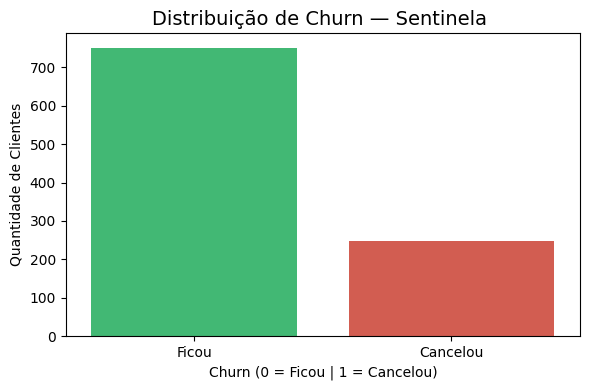

In [28]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='churn', palette=['#2ecc71','#e74c3c'])
plt.title('Distribuição de Churn — Sentinela ', fontsize=14)
plt.xlabel('Churn (0 = Ficou | 1 = Cancelou)')
plt.ylabel('Quantidade de Clientes')
plt.xticks([0,1], ['Ficou', 'Cancelou'])
plt.tight_layout()
plt.show()

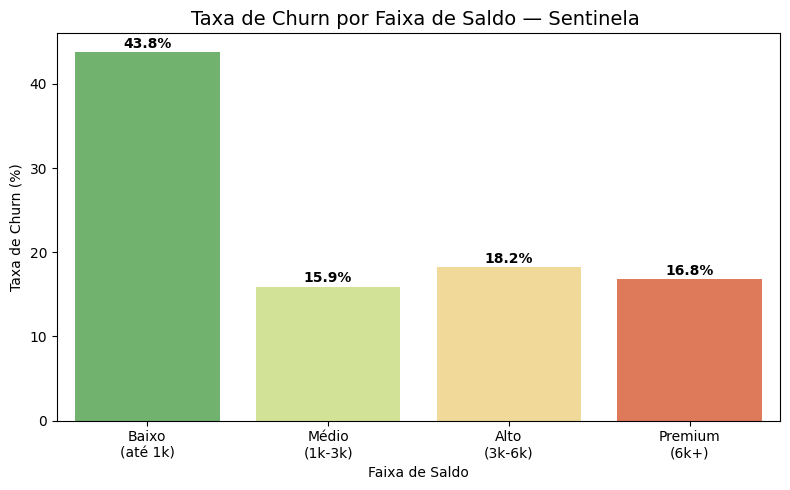

In [29]:
plt.figure(figsize=(8,5))
df['faixa_saldo'] = pd.cut(df['saldo_medio'],
                            bins=[0, 1000, 3000, 6000, 25000],
                            labels=['Baixo\n(até 1k)', 'Médio\n(1k-3k)',
                                   'Alto\n(3k-6k)', 'Premium\n(6k+)'])

taxa_churn = df.groupby('faixa_saldo', observed=True)['churn'].mean() * 100

sns.barplot(x=taxa_churn.index, y=taxa_churn.values, palette='RdYlGn_r')
plt.title('Taxa de Churn por Faixa de Saldo — Sentinela ', fontsize=14)
plt.xlabel('Faixa de Saldo')
plt.ylabel('Taxa de Churn (%)')

for i, v in enumerate(taxa_churn.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

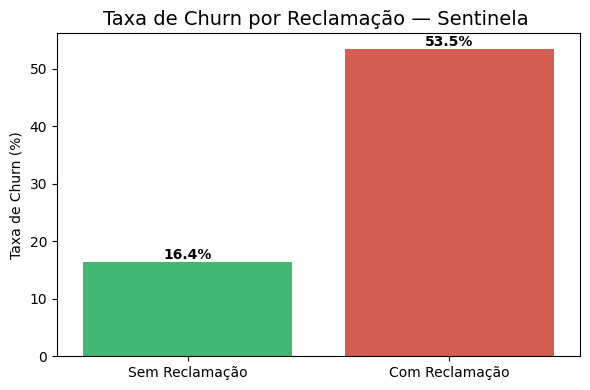

In [30]:
plt.figure(figsize=(6,4))

taxa_reclamacao = df.groupby('reclamacao_recente')['churn'].mean() * 100

sns.barplot(x=['Sem Reclamação', 'Com Reclamação'],
            y=taxa_reclamacao.values,
            palette=['#2ecc71','#e74c3c'])

plt.title('Taxa de Churn por Reclamação — Sentinela ', fontsize=14)
plt.ylabel('Taxa de Churn (%)')

for i, v in enumerate(taxa_reclamacao.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

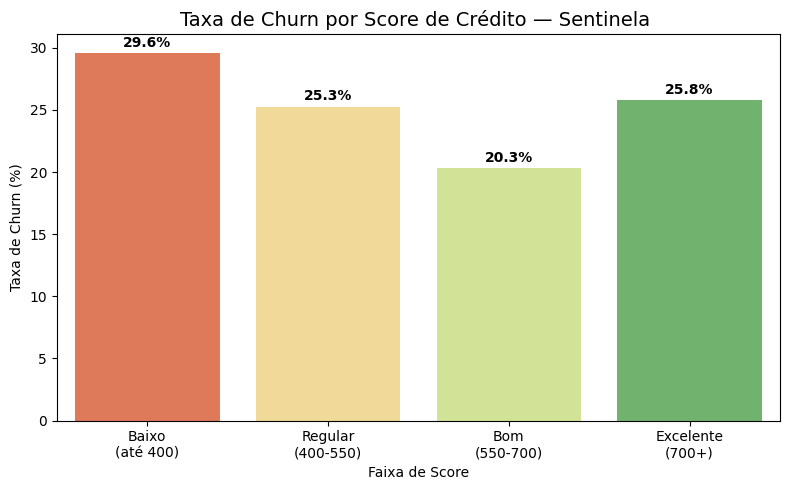

In [31]:
plt.figure(figsize=(8,5))

df['faixa_score'] = pd.cut(df['score_credito'],
                            bins=[0, 400, 550, 700, 850],
                            labels=['Baixo\n(até 400)', 'Regular\n(400-550)',
                                   'Bom\n(550-700)', 'Excelente\n(700+)'])

taxa_score = df.groupby('faixa_score', observed=True)['churn'].mean() * 100

sns.barplot(x=taxa_score.index, y=taxa_score.values, palette='RdYlGn')
plt.title('Taxa de Churn por Score de Crédito — Sentinela ', fontsize=14)
plt.xlabel('Faixa de Score')
plt.ylabel('Taxa de Churn (%)')

for i, v in enumerate(taxa_score.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

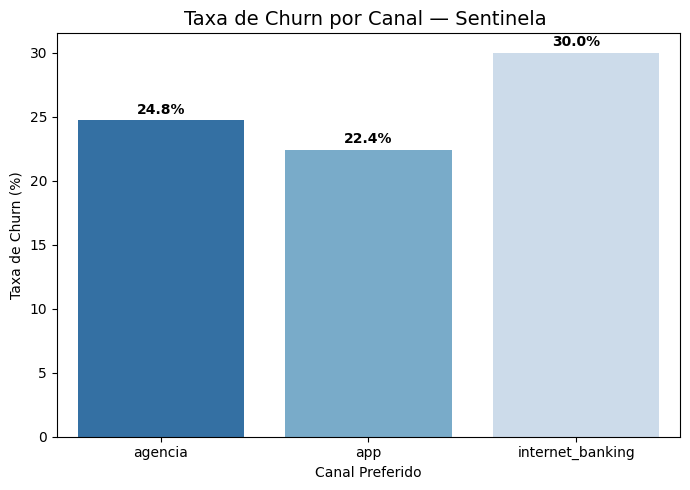

In [32]:
plt.figure(figsize=(7,5))

taxa_canal = df.groupby('canal_preferido')['churn'].mean() * 100

sns.barplot(x=taxa_canal.index, y=taxa_canal.values, palette='Blues_r')
plt.title('Taxa de Churn por Canal — Sentinela ', fontsize=14)
plt.xlabel('Canal Preferido')
plt.ylabel('Taxa de Churn (%)')

for i, v in enumerate(taxa_canal.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Passo 5 — SQL

Usamos SQL para fazer perguntas aos dados

1. Quais faixas de saldo concentram mais churn?
2. Como é o perfil de quem cancela vs quem fica?
3. Quais clientes precisam de atenção agora?

In [33]:
import sqlite3

conn = sqlite3.connect(':memory:')

df.to_sql('clientes', conn, index=False, if_exists='replace')

print("Banco de dados criado com sucesso!")
print("Tabela 'clientes' pronta para consultas SQL!")

Banco de dados criado com sucesso!
Tabela 'clientes' pronta para consultas SQL!


In [34]:
query1 = """
SELECT
    CASE
        WHEN saldo_medio < 1000 THEN 'Baixo (até 1k)'
        WHEN saldo_medio < 3000 THEN 'Médio (1k-3k)'
        WHEN saldo_medio < 6000 THEN 'Alto (3k-6k)'
        ELSE 'Premium (6k+)'
    END AS faixa_saldo,

    COUNT(*) AS total_clientes,
    SUM(churn) AS total_churn,
    ROUND(AVG(churn) * 100, 1) AS taxa_churn_pct

FROM clientes
GROUP BY faixa_saldo
ORDER BY taxa_churn_pct DESC
"""

resultado1 = pd.read_sql_query(query1, conn)
print("Taxa de Churn por Faixa de Saldo:")
display(resultado1)

Taxa de Churn por Faixa de Saldo:


,faixa_saldo,total_clientes,total_churn,taxa_churn_pct
0,Baixo (até 1k),299,131,43.8
1,Alto (3k-6k),225,41,18.2
2,Premium (6k+),143,24,16.8
3,Médio (1k-3k),333,53,15.9


In [35]:
query2 = """
SELECT
    CASE WHEN churn = 1 THEN 'Cancelou' ELSE 'Ficou' END AS perfil,
    COUNT(*) AS total_clientes,
    ROUND(AVG(idade), 1) AS idade_media,
    ROUND(AVG(saldo_medio), 2) AS saldo_medio,
    ROUND(AVG(score_credito), 1) AS score_medio,
    ROUND(AVG(num_transacoes), 1) AS transacoes_media,
    ROUND(AVG(produtos_contratados), 1) AS produtos_medio

FROM clientes
GROUP BY churn
"""

resultado2 = pd.read_sql_query(query2, conn)
print("Perfil do Cliente:")
display(resultado2)

Perfil do Cliente:


,perfil,total_clientes,idade_media,saldo_medio,score_medio,transacoes_media,produtos_medio
0,Ficou,751,43.3,3253.67,577.1,24.9,3.1
1,Cancelou,249,45.4,2197.33,567.1,21.5,2.8


In [36]:
query3 = """
SELECT
    cliente_id,
    idade,
    ROUND(saldo_medio, 2) AS saldo,
    score_credito,
    num_transacoes,
    produtos_contratados,
    reclamacao_recente,
    canal_preferido

FROM clientes
WHERE
    saldo_medio < 1000
    AND reclamacao_recente = 1
    AND score_credito < 500

ORDER BY saldo_medio ASC
LIMIT 10
"""

resultado3 = pd.read_sql_query(query3, conn)
print("Top 10 Clientes em Alto Risco:")
display(resultado3)

Top 10 Clientes em Alto Risco:


,cliente_id,idade,saldo,score_credito,num_transacoes,produtos_contratados,reclamacao_recente,canal_preferido
0,800,19,91.30,379,47,2,1,app
1,858,25,228.04,445,32,1,1,app
2,325,42,259.28,413,29,2,1,internet_banking
3,264,53,268.16,424,14,4,1,internet_banking
4,360,44,288.15,400,28,4,1,internet_banking
5,932,20,301.24,495,49,3,1,app
6,549,41,324.46,317,40,5,1,internet_banking
7,958,43,329.81,303,45,4,1,app
8,730,45,423.20,413,26,5,1,app
9,119,59,449.93,313,42,2,1,internet_banking


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("Bibliotecas de ML carregadas!")

Bibliotecas de ML carregadas!


In [38]:

df_ml = pd.get_dummies(df, columns=['canal_preferido'], drop_first=False)

df_ml = df_ml.drop(['cliente_id', 'faixa_saldo', 'faixa_score'], axis=1)

X = df_ml.drop('churn', axis=1)
y = df_ml['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dados preparados!")
print(f"Treino: {X_train.shape[0]} clientes")
print(f"Teste: {X_test.shape[0]} clientes")
print(f"Variáveis usadas: {X.shape[1]}")

Dados preparados!
Treino: 800 clientes
Teste: 200 clientes
Variáveis usadas: 11


In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelo = LogisticRegression(random_state=42)
modelo.fit(X_train_scaled, y_train)

print("Modelo treinado com sucesso!")
print("O Sentinela já sabe identificar clientes em risco!")

Modelo treinado com sucesso!
O Sentinela já sabe identificar clientes em risco!


Relatório de Desempenho do Sentinela:
              precision    recall  f1-score   support

       Ficou       0.81      0.91      0.86       150
    Cancelou       0.56      0.36      0.44        50

    accuracy                           0.77       200
   macro avg       0.69      0.63      0.65       200
weighted avg       0.75      0.77      0.75       200


Matriz de Confusão:


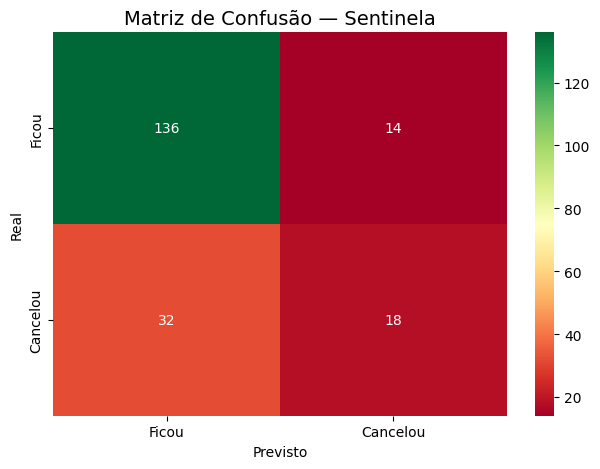

In [40]:

y_pred = modelo.predict(X_test_scaled)

print("Relatório de Desempenho do Sentinela:")
print("="*50)
print(classification_report(y_test, y_pred,
      target_names=['Ficou', 'Cancelou']))

print("\nMatriz de Confusão:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='RdYlGn',
            xticklabels=['Ficou', 'Cancelou'],
            yticklabels=['Ficou', 'Cancelou'])
plt.title('Matriz de Confusão — Sentinela', fontsize=14)
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.tight_layout()
plt.show()

Relatório de Desempenho — Sentinela V2:
              precision    recall  f1-score   support

       Ficou       0.87      0.73      0.79       150
    Cancelou       0.45      0.66      0.53        50

    accuracy                           0.71       200
   macro avg       0.66      0.69      0.66       200
weighted avg       0.76      0.71      0.73       200



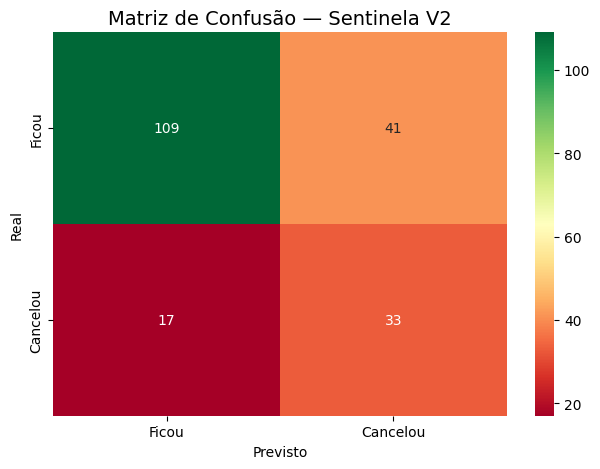

In [41]:
modelo_v2 = LogisticRegression(
    random_state=42,
    class_weight='balanced'  # Agora presta mais atenção no churn!
)
modelo_v2.fit(X_train_scaled, y_train)

y_pred_v2 = modelo_v2.predict(X_test_scaled)

print("Relatório de Desempenho — Sentinela V2:")
print("="*50)
print(classification_report(y_test, y_pred_v2,
      target_names=['Ficou', 'Cancelou']))

cm_v2 = confusion_matrix(y_test, y_pred_v2)
sns.heatmap(cm_v2, annot=True, fmt='d', cmap='RdYlGn',
            xticklabels=['Ficou', 'Cancelou'],
            yticklabels=['Ficou', 'Cancelou'])
plt.title('Matriz de Confusão — Sentinela V2', fontsize=14)
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.tight_layout()
plt.show()

Relatório de Desempenho — Sentinela V3:
              precision    recall  f1-score   support

       Ficou       0.78      0.93      0.85       150
    Cancelou       0.52      0.22      0.31        50

    accuracy                           0.76       200
   macro avg       0.65      0.58      0.58       200
weighted avg       0.72      0.76      0.72       200



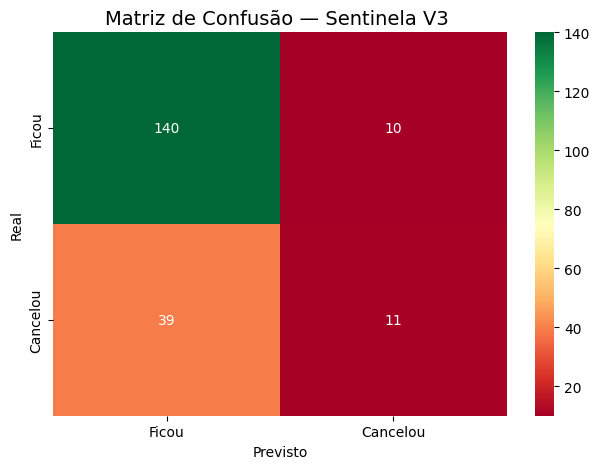

In [42]:
from sklearn.ensemble import RandomForestClassifier

modelo_v3 = RandomForestClassifier(
    n_estimators=100,      # 100 árvores de decisão votando
    class_weight='balanced', # Ainda balanceado para churn
    random_state=42
)
modelo_v3.fit(X_train_scaled, y_train)

y_pred_v3 = modelo_v3.predict(X_test_scaled)

print("Relatório de Desempenho — Sentinela V3:")
print("="*50)
print(classification_report(y_test, y_pred_v3,
      target_names=['Ficou', 'Cancelou']))

cm_v3 = confusion_matrix(y_test, y_pred_v3)
sns.heatmap(cm_v3, annot=True, fmt='d', cmap='RdYlGn',
            xticklabels=['Ficou', 'Cancelou'],
            yticklabels=['Ficou', 'Cancelou'])
plt.title('Matriz de Confusão — Sentinela V3 ', fontsize=14)
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.tight_layout()
plt.show()

In [43]:
from google.colab import files
files.download('clientes_banco.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

colunas_modelo = X_train.columns.tolist()
print("Colunas do modelo:", colunas_modelo)

novo_cliente = pd.DataFrame({
    'idade':                [35],
    'saldo_medio':          [800],
    'num_transacoes':       [3],
    'produtos_contratados': [1],
    'tempo_como_cliente':   [12],
    'reclamacao_recente':   [1],
    'score_credito':        [420],
    'renda_mensal':         [2500],
    'canal_preferido_agencia':         [0],
    'canal_preferido_app':             [0],
    'canal_preferido_internet_banking':[1],
    'faixa_saldo':          [0],
    'faixa_score':          [0]
})

novo_cliente = novo_cliente[colunas_modelo]

novo_scaled = scaler.transform(novo_cliente)

probabilidade = modelo_v2.predict_proba(novo_scaled)[0][1]
previsao = modelo_v2.predict(novo_scaled)[0]

print("=" * 45)
print("  SENTINELA V2 — RESULTADO DA ANALISE")
print("=" * 45)
print(f"  Probabilidade de churn:  {probabilidade*100:.1f}%")
print(f"  Classificacao: {'ALTO RISCO' if previsao == 1 else 'BAIXO RISCO'}")
print("=" * 45)

if previsao == 1:
    print("\n  ALERTA: Cliente em risco de cancelamento!")
    print("  Acionar time de retencao imediatamente.")
else:
    print("\n  Cliente com baixo risco de cancelamento.")
    print("  Monitorar periodicamente.")

Colunas do modelo: ['idade', 'saldo_medio', 'num_transacoes', 'produtos_contratados', 'tempo_como_cliente', 'reclamacao_recente', 'score_credito', 'renda_mensal', 'canal_preferido_agencia', 'canal_preferido_app', 'canal_preferido_internet_banking']
  SENTINELA V2 — RESULTADO DA ANALISE
  Probabilidade de churn:  93.1%
  Classificacao: ALTO RISCO

  ALERTA: Cliente em risco de cancelamento!
  Acionar time de retencao imediatamente.
